# Dépenses de médicaments remboursés en France : pourquoi augmentent-elles alors que l'on consomme moins de boîtes ?

**Auteure :** Fatima-Zahra FRINDOU · [GitHub](https://github.com/Fatima-Zahra37)

**Contexte :** l'Assurance Maladie rembourse chaque année plus de 26 milliards d'euros de médicaments délivrés en pharmacie de ville. Cette analyse compare 2024 et 2025 pour comprendre ce qui fait évoluer cette dépense, avec un regard particulier sur la région Centre-Val de Loire.

**Question métier :** pourquoi les dépenses de médicaments remboursés augmentent-elles entre 2024 et 2025, alors que le nombre de boîtes baisse ?

**Résultat clé :** +1,4 Md€ (+5,4 %) en un an, porté à 83 % par 10 molécules seulement, et à 78 % par les patients de 60 ans et plus.

**Source :** [Open Medic, base complète sur les dépenses de médicaments interrégimes](https://www.data.gouv.fr/datasets/open-medic-base-complete-sur-les-depenses-de-medicaments-interregimes) (Assurance Maladie, data.gouv.fr, licence ouverte), années 2024 et 2025, soit environ 3,8 millions de lignes.

**Outils :** Python (Pandas, Matplotlib), SQL (DuckDB), Power BI.

**Plan :** 1. Chargement · 2. Découverte · 3. Contrôles qualité · 4. Cadrage · 5. Préparation · 6. Analyse · 7. Validation SQL · 8. Export · 9. Conclusions

In [1]:
# Bibliothèques utilisées
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import duckdb

pd.set_option("display.max_columns", None)   # afficher toutes les colonnes

## 1. Chargement des données

### 1.1 Chargement du fichier 2024

In [2]:
df_2024=pd.read_csv("../data/raw/OPEN_MEDIC_2024.csv", sep=";", low_memory=False, encoding="latin-1", decimal=",", thousands=".")
print(df_2024.shape)

(1916885, 21)


### 1.2 Chargement du fichier 2025

In [3]:
df_2025=pd.read_csv("../data/raw/OPEN_MEDIC_2025.csv", sep=";", low_memory=False, encoding="latin-1", decimal=",", thousands=".")
print(df_2025.shape)

(1873062, 21)


## 2. Découvrir les données

### 2.1 Les données du fichier 2024

In [4]:
 # observer les premières lignes 
df_2024.head(5)

,ATC1,l_ATC1,ATC2,L_ATC2,ATC3,L_ATC3,ATC4,L_ATC4,ATC5,L_ATC5,CIP13,l_cip13,TOP_GEN,GEN_NUM,age,sexe,BEN_REG,PSP_SPE,BOITES,REM,BSE
0,A,SYSTEME DIGESTIF ET METABOLISME,A01,PREPARATIONS STOMATOLOGIQUES,A01A,PREPARATIONS STOMATOLOGIQUES,A01AA,MEDICAMENTS PROPHYLACTIQUES ANTICARIES,A01AA01,SODIUM FLUORURE,3400932387656,FLUOGEL GEL DENTAIRE 1,0,0,99,9,99,99,14,38.54,51.38
1,A,SYSTEME DIGESTIF ET METABOLISME,A01,PREPARATIONS STOMATOLOGIQUES,A01A,PREPARATIONS STOMATOLOGIQUES,A01AA,MEDICAMENTS PROPHYLACTIQUES ANTICARIES,A01AA01,SODIUM FLUORURE,3400934089480,"ZYMAFLUOR 0,50MG CPR 100",0,0,0,1,5,1,25,13.06,41.45
2,A,SYSTEME DIGESTIF ET METABOLISME,A01,PREPARATIONS STOMATOLOGIQUES,A01A,PREPARATIONS STOMATOLOGIQUES,A01AA,MEDICAMENTS PROPHYLACTIQUES ANTICARIES,A01AA01,SODIUM FLUORURE,3400934089480,"ZYMAFLUOR 0,50MG CPR 100",0,0,0,1,5,99,20,10.18,33.92
3,A,SYSTEME DIGESTIF ET METABOLISME,A01,PREPARATIONS STOMATOLOGIQUES,A01A,PREPARATIONS STOMATOLOGIQUES,A01AA,MEDICAMENTS PROPHYLACTIQUES ANTICARIES,A01AA01,SODIUM FLUORURE,3400934089480,"ZYMAFLUOR 0,50MG CPR 100",0,0,0,1,11,1,114,48.89,147.48
4,A,SYSTEME DIGESTIF ET METABOLISME,A01,PREPARATIONS STOMATOLOGIQUES,A01A,PREPARATIONS STOMATOLOGIQUES,A01AA,MEDICAMENTS PROPHYLACTIQUES ANTICARIES,A01AA01,SODIUM FLUORURE,3400934089480,"ZYMAFLUOR 0,50MG CPR 100",0,0,0,1,11,12,404,157.83,521.16


In [5]:
# types et valeurs remplies 
df_2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 1916885 entries, 0 to 1916884
Data columns (total 21 columns):
 #   Column   Dtype  
---  ------   -----  
 0   ATC1     str    
 1   l_ATC1   str    
 2   ATC2     str    
 3   L_ATC2   str    
 4   ATC3     str    
 5   L_ATC3   str    
 6   ATC4     str    
 7   L_ATC4   str    
 8   ATC5     str    
 9   L_ATC5   str    
 10  CIP13    int64  
 11  l_cip13  str    
 12  TOP_GEN  int64  
 13  GEN_NUM  int64  
 14  age      int64  
 15  sexe     int64  
 16  BEN_REG  int64  
 17  PSP_SPE  int64  
 18  BOITES   int64  
 19  REM      float64
 20  BSE      float64
dtypes: float64(2), int64(8), str(11)
memory usage: 307.1 MB


In [6]:
# Diagnostic (déjà résolu) : REM restait en texte après decimal=","
# Cause : point des milliers dans les grands montants (ex. 1.761,57)
# Solution : ajout de thousands="." au chargement
# df_2024.loc[df_2024["REM"].str.contains(r"[^0-9,\-]"), "REM"].head(10)

In [7]:
# valeurs manquantes par colonne 
df_2024.isna().sum()

ATC1       0
l_ATC1     0
ATC2       0
L_ATC2     0
ATC3       0
L_ATC3     0
ATC4       0
L_ATC4     0
ATC5       0
L_ATC5     0
CIP13      0
l_cip13    0
TOP_GEN    0
GEN_NUM    0
age        0
sexe       0
BEN_REG    0
PSP_SPE    0
BOITES     0
REM        0
BSE        0
dtype: int64

In [8]:
 # nombre de valeurs différentes 
df_2024.nunique()

ATC1           14
l_ATC1         14
ATC2           79
L_ATC2         79
ATC3          187
L_ATC3        186
ATC4          448
L_ATC4        430
ATC5         1166
L_ATC5       1091
CIP13       12646
l_cip13     12228
TOP_GEN         4
GEN_NUM       726
age             4
sexe            3
BEN_REG        14
PSP_SPE        27
BOITES      32855
REM        598440
BSE        564522
dtype: int64

In [9]:
# répartition de la colonne "age"
df_2024["age"].value_counts() 

age
60    862623
20    773815
0     271186
99      9261
Name: count, dtype: int64

In [10]:
# répartition de la colonne "sexe"
df_2024["sexe"].value_counts()

sexe
2    1010716
1     902739
9       3430
Name: count, dtype: int64

In [11]:
# répartition de la colonne "TOP_GEN"
df_2024["TOP_GEN"].value_counts()

TOP_GEN
1    1136868
0     577966
4     202034
9         17
Name: count, dtype: int64

In [12]:
# répartition de la colonne "BEN_REG"
df_2024["BEN_REG"].value_counts()

BEN_REG
11    245244
93    182086
76    171863
84    167724
75    156677
44    147024
32    145659
28    116068
52    115874
24    112895
27    109325
53    108330
5      80761
99     57355
Name: count, dtype: int64

In [13]:
# répartition de la colonne "PSP_SPE"
df_2024["PSP_SPE"].value_counts()

PSP_SPE
1     468138
90    406196
99    306879
3      72836
4      67853
17     54452
15     43123
98     42605
19     40869
7      40462
5      38663
11     35577
42     35419
6      35245
12     34395
13     32868
14     32798
8      30050
9      25619
32     23617
2      16134
18     14447
35     13007
31      4526
36       695
38       385
37        27
Name: count, dtype: int64

In [14]:
# répartition de la colonne "ATC1"
df_2024["ATC1"].value_counts()

ATC1
N    393988
C    364151
A    304686
J    185406
R    135446
D     93298
M     87629
B     76534
S     65741
H     65690
G     54431
L     52111
V     26750
P     11024
Name: count, dtype: int64

In [15]:
# répartition des grandes classes de médicaments (ATC1)
df_2024[["ATC1", "l_ATC1"]].value_counts()

ATC1  l_ATC1                                                                     
N     SYSTEME NERVEUX                                                                393988
C     SYSTEME CARDIO-VASCULAIRE                                                      364151
A     SYSTEME DIGESTIF ET METABOLISME                                                304686
J     ANTI-INFECTIEUX (USAGE SYSTEMIQUE)                                             185406
R     SYSTEME RESPIRATOIRE                                                           135446
D     DERMATOLOGIE                                                                    93298
M     SYSTEME MUSCULO-SQUELETTIQUE                                                    87629
B     SANG ET ORGANES HEMATOPOIETQUES                                                 76534
S     ORGANES SENSORIELS                                                              65741
H     HORMONES SYSTEMIQUES, A L EXCLUSION DES HORMONES SEXUELLES ET DES INSULINES     6569

### 2.2 Les données du fichier 2025

In [16]:
 # observer les premières lignes 
df_2025.head(5)

,ATC1,l_ATC1,ATC2,L_ATC2,ATC3,L_ATC3,ATC4,L_ATC4,ATC5,L_ATC5,CIP13,l_cip13,TOP_GEN,GEN_NUM,age,sexe,BEN_REG,PSP_SPE,BOITES,REM,BSE
0,A,Systme digestif et mtabolisme,A01,PREPARATIONS STOMATOLOGIQUES,A01A,PREPARATIONS STOMATOLOGIQUES,A01AA,MEDICAMENTS PROPHYLACTIQUES ANTICARIES,A01AA01,SODIUM FLUORURE,3400932387656,FLUOGEL GEL DENTAIRE 1,0,0,99,9,99,99,41,135.06,150.47
1,A,Systme digestif et mtabolisme,A01,PREPARATIONS STOMATOLOGIQUES,A01A,PREPARATIONS STOMATOLOGIQUES,A01AA,MEDICAMENTS PROPHYLACTIQUES ANTICARIES,A01AA02,SODIUM MONOFLUOROPHOSPHATE,3400932409860,FLUOGEL 2000 GEL DENTAIRE 1,0,0,0,1,11,90,33,169.71,351.12
2,A,Systme digestif et mtabolisme,A01,PREPARATIONS STOMATOLOGIQUES,A01A,PREPARATIONS STOMATOLOGIQUES,A01AA,MEDICAMENTS PROPHYLACTIQUES ANTICARIES,A01AA02,SODIUM MONOFLUOROPHOSPHATE,3400932409860,FLUOGEL 2000 GEL DENTAIRE 1,0,0,0,1,11,98,79,256.96,840.56
3,A,Systme digestif et mtabolisme,A01,PREPARATIONS STOMATOLOGIQUES,A01A,PREPARATIONS STOMATOLOGIQUES,A01AA,MEDICAMENTS PROPHYLACTIQUES ANTICARIES,A01AA02,SODIUM MONOFLUOROPHOSPHATE,3400932409860,FLUOGEL 2000 GEL DENTAIRE 1,0,0,0,1,11,99,19,110.12,202.16
4,A,Systme digestif et mtabolisme,A01,PREPARATIONS STOMATOLOGIQUES,A01A,PREPARATIONS STOMATOLOGIQUES,A01AA,MEDICAMENTS PROPHYLACTIQUES ANTICARIES,A01AA02,SODIUM MONOFLUOROPHOSPHATE,3400932409860,FLUOGEL 2000 GEL DENTAIRE 1,0,0,0,1,24,98,23,73.42,244.72


In [17]:
# types et valeurs remplies 
df_2025.info()

<class 'pandas.DataFrame'>
RangeIndex: 1873062 entries, 0 to 1873061
Data columns (total 21 columns):
 #   Column   Dtype  
---  ------   -----  
 0   ATC1     str    
 1   l_ATC1   str    
 2   ATC2     str    
 3   L_ATC2   str    
 4   ATC3     str    
 5   L_ATC3   str    
 6   ATC4     str    
 7   L_ATC4   str    
 8   ATC5     str    
 9   L_ATC5   str    
 10  CIP13    int64  
 11  l_cip13  str    
 12  TOP_GEN  int64  
 13  GEN_NUM  int64  
 14  age      int64  
 15  sexe     int64  
 16  BEN_REG  int64  
 17  PSP_SPE  int64  
 18  BOITES   int64  
 19  REM      float64
 20  BSE      float64
dtypes: float64(2), int64(8), str(11)
memory usage: 300.1 MB


In [18]:
# nombre de valeurs différentes 
df_2025.nunique()

ATC1           14
l_ATC1         14
ATC2           79
L_ATC2         79
ATC3          188
L_ATC3        187
ATC4          451
L_ATC4        432
ATC5         1170
L_ATC5       1097
CIP13       12505
l_cip13     12101
TOP_GEN         4
GEN_NUM       715
age             4
sexe            3
BEN_REG        14
PSP_SPE        25
BOITES      32651
REM        601623
BSE        559046
dtype: int64

In [19]:
 # répartition de la colonne "age"
df_2025["age"].value_counts()

age
60    849486
20    750335
0     262027
99     11214
Name: count, dtype: int64

In [20]:
# répartition de la colonne "sexe"
df_2025["sexe"].value_counts()

sexe
2    985761
1    884973
9      2328
Name: count, dtype: int64

In [21]:
# répartition de la colonne "TOP_GEN"
df_2025["TOP_GEN"].value_counts()

TOP_GEN
1    1136037
0     547370
4     189641
9         14
Name: count, dtype: int64

In [22]:
# répartition de la colonne "BEN_REG"
df_2025["BEN_REG"].value_counts()

BEN_REG
11    239555
93    178852
76    167050
84    164116
75    152454
32    143198
44    142388
52    114110
28    114026
24    111776
27    107543
53    105714
5      80002
99     52278
Name: count, dtype: int64

In [23]:
# répartition de la colonne "PSP_SPE"
df_2025["PSP_SPE"].value_counts()

PSP_SPE
1     460160
90    404485
99    303143
98     79258
3      73036
4      63956
17     56009
15     39727
7      37449
5      36489
42     35914
11     32899
12     32121
8      32020
14     31501
13     31297
6      26311
9      25980
32     24624
2      14545
18     13809
35     13578
31      4284
38       375
37        92
Name: count, dtype: int64

In [24]:
# répartition de la colonne "ATC1"
df_2025["ATC1"].value_counts()

ATC1
N    386860
C    372977
A    299482
J    171742
R    135177
D     89487
M     85349
B     79246
H     62343
S     61993
L     54077
G     52032
V     11502
P     10795
Name: count, dtype: int64

In [25]:
# répartition des grandes classes de médicaments (ATC1)
df_2025[["ATC1", "l_ATC1"]].value_counts()

ATC1  l_ATC1                                                                     
N     Systme nerveux                                                                386860
C     Systme cardio-vasculaire                                                      372977
A     Systme digestif et mtabolisme                                                299482
J     Anti-infectieux (usage systmique)                                             171742
R     Systme respiratoire                                                           135177
D     Dermatologie                                                                    89487
M     Systme musculo-squelettique                                                    85349
B     Sang et organes hmatopoitiques                                                79246
H     Hormones systmiques,  l exclusion des hormones sexuelles et des insulines     62343
S     Organes sensoriels                                                              6199

### 2.3 Synthèse de la découverte

**Constat des fichiers**
- Séparateur `;` et encodage `latin-1` (la lecture par défaut en UTF-8 échoue)
- 2024 : 1 916 885 lignes / 2025 : 1 873 062 lignes, 21 colonnes identiques
- Une ligne = une combinaison médicament × âge × sexe × région × spécialité du prescripteur (pas un patient)

**Types de données**
- `REM` et `BSE` : virgule décimale et point des milliers (ex. `1.761,57`) → corrigé au chargement avec `decimal=","` et `thousands="."`
- `age`, `sexe`, `BEN_REG`, `PSP_SPE`, `TOP_GEN` sont des codes, pas des valeurs à calculer

**Valeurs manquantes**
- Aucune valeur vide, mais les inconnus sont codés `99` ou `9`
- Part d'inconnus la plus forte : spécialité du prescripteur (`PSP_SPE` = 99, environ 16 %)

**Codes à identifier avec une source officielle**
- `TOP_GEN` (valeurs 0, 1, 4, 9)
- `BEN_REG` : code `5` (Corse et outre-mer ?)
- `PSP_SPE` : liste des spécialités, dont `90` et `98`
- `age` : tranches supposées 0-19, 20-59, 60 et plus

**Différences entre 2024 et 2025**
- `PSP_SPE` : codes `19` et `36` disparus en 2025, code `98` presque doublé → probable reclassement
- `ATC1` : catégorie `V` (Divers) en baisse de 57 % → à vérifier
- Libellés `l_ATC1` en 2025 : accents perdus → comparer par les codes, pas par les libellés

## 3. Contrôles qualité
Vérifier que les quantités et les montants sont cohérents avant de les analyser.

In [26]:
# 3.1 Statistiques des quantités et montants - 2024
df_2024[["BOITES", "REM", "BSE"]].describe().round(2)

,BOITES,REM,BSE
count,1916885.00,1916885.00,1916885.00
mean,1235.32,13580.29,15504.15
std,18296.43,196778.45,203963.58
min,-44.00,-389.00,-163.13
25%,38.00,125.74,184.86
50%,94.00,438.10,603.75
75%,362.00,2192.31,2960.33
max,6443899.00,46172782.62,47120345.73


**Constat 2024 :**
- Valeurs négatives présentes (min : −44 boîtes, −389 € remboursés) : probablement des corrections comptables (boîtes rendues, remboursements annulés). À compter.
- Moyenne remboursée par ligne (13 580 €) bien supérieure à la médiane (438 €) : quelques lignes très élevées concentrent l'essentiel des montants. On analysera avec des totaux et la médiane plutôt que la moyenne.
- Maximums très élevés (6,4 millions de boîtes, 46 M€ sur une ligne) mais plausibles pour des médicaments très prescrits ou coûteux. À identifier pendant l'analyse.

In [27]:
# 3.1 Statistiques des quantités et montants - 2025
df_2025[["BOITES", "REM", "BSE"]].describe().round(2)

,BOITES,REM,BSE
count,1873062.00,1873062.00,1873062.00
mean,1242.25,14651.11,16784.83
std,17552.96,215792.67,226832.50
min,-6.00,-280.98,-19.44
25%,39.00,133.40,194.85
50%,97.00,460.00,634.66
75%,379.00,2336.08,3153.02
max,6078276.00,54982984.80,55670240.34


**Constat 2025 :**
- Valeurs négatives toujours présentes, mais plus faibles (min : −6 boîtes, −281 € remboursés).
- Montant remboursé par ligne en hausse par rapport à 2024 : moyenne +8 % (14 651 €), médiane +5 % (460 €).
- Maximum en forte hausse : 55 M€ sur une ligne (+19 % par rapport à 2024).
- Piste à vérifier avec les totaux : moins de lignes, mais une dépense par ligne plus élevée, peut-être liée à des médicaments plus chers.

In [28]:
# 3.2 Nombre de valeurs négatives par colonne - 2024
(df_2024[["BOITES", "REM", "BSE"]] < 0).sum()

BOITES    24
REM       55
BSE       24
dtype: int64

**Constat 2024 :** 24 lignes avec des boîtes négatives, 55 avec un remboursement négatif (moins de 0,003 % des lignes). Probables corrections comptables (retours, remboursements corrigés). Décision : lignes conservées, car elles font partie de la dépense réelle.

In [29]:
# 3.2 Nombre de valeurs négatives par colonne - 2025
(df_2025[["BOITES", "REM", "BSE"]] < 0).sum()

BOITES    2
REM       6
BSE       1
dtype: int64

**Constat 2025 :** 2 lignes avec des boîtes négatives, 6 avec un remboursement négatif, 1 avec une base négative : beaucoup moins qu'en 2024. Hypothèse : année plus récente, donc moins de corrections enregistrées. Décision : lignes conservées, comme en 2024.

In [30]:
# 3.3 Doublons : même boîte, même âge, même sexe, même région, même prescripteur - 2024
cle = ["CIP13", "age", "sexe", "BEN_REG", "PSP_SPE"]
df_2024.duplicated(subset=cle).sum()

np.int64(3)

In [31]:
# Afficher les lignes en double (les 2 exemplaires de chaque doublon)
doublons_2024 = df_2024[df_2024.duplicated(subset=cle, keep=False)]
doublons_2024[cle + ["l_cip13", "TOP_GEN", "BOITES", "REM"]].sort_values(cle)

,CIP13,age,sexe,BEN_REG,PSP_SPE,l_cip13,TOP_GEN,BOITES,REM
847956,9999999999999,20,2,99,1,INCONNU,9,12,25.00
952842,9999999999999,20,2,99,1,INCONNU,9,16,28.32
559561,9999999999999,60,2,11,1,INCONNU,9,12,64.36
668042,9999999999999,60,2,11,1,INCONNU,9,33,144.34
698728,9999999999999,60,2,11,1,INCONNU,9,20,99.11


**Constat 2024 :** 3 doublons sur la clé (boîte, âge, sexe, région, spécialité). Ce ne sont pas de vrais doublons : il s'agit de boîtes non identifiées (code `9999999999999`, libellé INCONNU, `TOP_GEN` = 9), avec des montants différents. Décision : lignes conservées.

In [32]:
# 3.3 Doublons - 2025
df_2025.duplicated(subset=cle).sum()

np.int64(8)

In [33]:
# Afficher les lignes en double - 2025
doublons_2025 = df_2025[df_2025.duplicated(subset=cle, keep=False)]
doublons_2025[cle + ["l_cip13", "TOP_GEN", "BOITES", "REM"]].sort_values(cle)

,CIP13,age,sexe,BEN_REG,PSP_SPE,l_cip13,TOP_GEN,BOITES,REM
556697,9999999999999,60,1,11,1,INCONNU,9,15,119.44
713061,9999999999999,60,1,11,1,INCONNU,9,11,73.79
713063,9999999999999,60,1,11,1,INCONNU,9,39,248.79
208625,9999999999999,60,2,11,1,INCONNU,9,23,60.10
364027,9999999999999,60,2,11,1,INCONNU,9,1168,2897.43
618896,9999999999999,60,2,11,1,INCONNU,9,19,127.92
713060,9999999999999,60,2,11,1,INCONNU,9,40,190.32
713062,9999999999999,60,2,11,1,INCONNU,9,11,72.20
713065,9999999999999,60,2,11,1,INCONNU,9,31,186.30
364028,9999999999999,60,2,11,90,INCONNU,9,278,570.13


**Constat 2025 :** 8 doublons sur la clé, tous sur des boîtes non identifiées (code `9999999999999`, INCONNU, `TOP_GEN` = 9), avec des montants différents. Même explication qu'en 2024. Décision : lignes conservées.

In [34]:
# 3.4 Totaux de contrôle - 2024
print(f"Montant remboursé : {df_2024['REM'].sum():,.0f} €".replace(",", " "))
print(f"Base de remboursement : {df_2024['BSE'].sum():,.0f} €".replace(",", " "))
print(f"Nombre de boîtes : {df_2024['BOITES'].sum():,.0f}".replace(",", " "))

Montant remboursé : 26 031 855 506 €
Base de remboursement : 29 719 673 619 €
Nombre de boîtes : 2 367 965 230


**Chiffres de référence 2024 :**
- Montant remboursé : 26,0 Md€
- Base de remboursement : 29,7 Md€
- Nombre de boîtes : 2,37 milliards
- Taux de remboursement moyen : 87,6 % ; remboursement moyen par boîte : environ 11 €
- Ces totaux serviront à valider les calculs en SQL et dans Power BI.

In [35]:
# 3.4 Totaux de contrôle - 2025
print(f"Montant remboursé : {df_2025['REM'].sum():,.0f} €".replace(",", " "))
print(f"Base de remboursement : {df_2025['BSE'].sum():,.0f} €".replace(",", " "))
print(f"Nombre de boîtes : {df_2025['BOITES'].sum():,.0f}".replace(",", " "))

Montant remboursé : 27 442 442 199 €
Base de remboursement : 31 439 023 945 €
Nombre de boîtes : 2 326 805 025


**Chiffres de référence 2025 :**
- Montant remboursé : 27,4 Md€ (+5,4 % par rapport à 2024)
- Base de remboursement : 31,4 Md€ (+5,8 %)
- Nombre de boîtes : 2,33 milliards (−1,7 %)
- Taux de remboursement moyen : 87,3 % ; remboursement moyen par boîte : 11,79 € (+7,3 %)
- Constat clé : moins de boîtes mais plus de dépenses. La hausse vient du coût par boîte, pas du volume. À expliquer dans l'analyse.

## 4. Cadrage de l'analyse

**Question métier :** pourquoi les dépenses de médicaments remboursés augmentent-elles entre 2024 et 2025, alors que le nombre de boîtes baisse ?

**Sous-questions :**
1. **Médicaments :** quelles classes de médicaments, puis quelles molécules, portent la hausse ?
2. **Génériques :** la part des génériques progresse-t-elle ?
3. **Patients :** quels profils (âge, sexe) concentrent la dépense ?
4. **Territoire :** le Centre-Val de Loire suit-il la tendance nationale ?

**Indicateurs :**
- Montant remboursé (en €) et nombre de boîtes
- Remboursement moyen par boîte (montant ÷ boîtes)
- Évolution 2024 → 2025 (en %)
- Part des génériques (en % des boîtes)

### Hypothèses de départ
| N° | Hypothèse | Vérifiée en |
|---|---|---|
| H1 | La hausse des dépenses vient du coût par boîte, pas du nombre de boîtes | 3.4 |
| H2 | La part des génériques progresse | 5.5 |
| H3 | La hausse des anti-infectieux vient des vaccins ou des antiviraux | 6.2 |
| H4 | La hausse en dermatologie vient de nouveaux traitements coûteux | 6.2 |
| H5 | Les 60 ans et plus concentrent la dépense | 6.3 |
| H6 | Le Centre-Val de Loire suit la tendance nationale | 6.4 |

## 5. Préparation des données
Garder les colonnes utiles à la question métier, assembler les deux années dans un seul tableau, et ajouter des libellés lisibles.

In [36]:
# 5.1 Colonnes utiles pour répondre aux sous-questions
colonnes_utiles = [
    "ATC1", "ATC5", "L_ATC5",       # Médicaments : classe et molécule
    "TOP_GEN",                       # Génériques
    "age", "sexe",                   # Patients
    "BEN_REG",                       # Territoire
    "BOITES", "REM", "BSE",          # Indicateurs
]

In [37]:
# 5.2 Assembler 2024 et 2025, avec une colonne "annee" pour les distinguer
df = pd.concat([
    df_2024[colonnes_utiles].assign(annee=2024),
    df_2025[colonnes_utiles].assign(annee=2025),
], ignore_index=True)

print(df.shape)

(3789947, 11)


In [38]:
# Contrôle automatique : les totaux doivent être identiques avant et après l'assemblage
reference = pd.DataFrame({
    2024: df_2024[["REM", "BSE", "BOITES"]].sum(),
    2025: df_2025[["REM", "BSE", "BOITES"]].sum(),
}).T

controle = df.groupby("annee")[["REM", "BSE", "BOITES"]].sum()

ecart = (controle - reference).abs().max().max()
print(f"Écart maximal : {ecart:.2f}")
assert ecart < 1, "Attention : les totaux ont changé !"

Écart maximal : 0.00


**Contrôle :** 3 789 947 lignes (1 916 885 + 1 873 062) et 11 colonnes. Totaux par année identiques à la section 3.4 (écart de 0 €) : aucune ligne perdue ni dupliquée lors de l'assemblage.

In [39]:
# 5.3 Libellés lisibles des classes de médicaments (ATC1)
# Écrits à la main : libellés 2025 abîmés, libellés 2024 sans accents
libelles_classe = {
    "A": "Digestif et métabolisme",
    "B": "Sang",
    "C": "Cardiovasculaire",
    "D": "Dermatologie",
    "G": "Génito-urinaire et hormones sexuelles",
    "H": "Hormones (hors sexuelles et insulines)",
    "J": "Anti-infectieux",
    "L": "Anticancéreux et immunité",
    "M": "Muscles et squelette",
    "N": "Système nerveux",
    "P": "Antiparasitaires",
    "R": "Respiratoire",
    "S": "Organes des sens",
    "V": "Divers",
}
df["classe"] = df["ATC1"].map(libelles_classe)

# Contrôle : aucune classe ne doit rester sans libellé
df["classe"].isna().sum()

np.int64(0)

In [40]:
# 5.4 Libellés lisibles : âge, sexe, région
# Correspondances à confirmer avec le descriptif officiel des variables
libelles_age = {0: "0-19 ans", 20: "20-59 ans", 60: "60 ans et plus", 99: "Inconnu"}
libelles_sexe = {1: "Homme", 2: "Femme", 9: "Inconnu"}
libelles_region = {
    11: "Île-de-France", 24: "Centre-Val de Loire", 27: "Bourgogne-Franche-Comté",
    28: "Normandie", 32: "Hauts-de-France", 44: "Grand Est",
    52: "Pays de la Loire", 53: "Bretagne", 75: "Nouvelle-Aquitaine",
    76: "Occitanie", 84: "Auvergne-Rhône-Alpes", 93: "Provence-Alpes-Côte d'Azur",
    5: "Code 5 (à confirmer)", 99: "Inconnu",
}

df["tranche_age"] = df["age"].map(libelles_age)
df["sexe_lib"] = df["sexe"].map(libelles_sexe)
df["region"] = df["BEN_REG"].map(libelles_region)

# Contrôle : aucune valeur sans libellé
df[["tranche_age", "sexe_lib", "region"]].isna().sum()

tranche_age    0
sexe_lib       0
region         0
dtype: int64

In [41]:
# 5.5 Libellés lisibles : statut générique
# 0 = princeps et 1 = générique (lecture courante, à confirmer avec le descriptif officiel)
libelles_gen = {
    0: "Princeps",
    1: "Générique",
    4: "Code 4 (à confirmer)",
    9: "Inconnu",
}
df["statut_gen"] = df["TOP_GEN"].map(libelles_gen)

# Contrôle : répartition des boîtes par statut et par année
df.groupby(["annee", "statut_gen"])["BOITES"].sum()

annee  statut_gen          
2024   Code 4 (à confirmer)     212367345
       Générique               1061663209
       Inconnu                        338
       Princeps                1093934338
2025   Code 4 (à confirmer)     184520569
       Générique               1073361159
       Inconnu                       1748
       Princeps                1068921549
Name: BOITES, dtype: int64

**Constat :** les génériques progressent (+1,1 % de boîtes) alors que les princeps (−2,3 %) et le code 4 (−13 %) reculent. Part des génériques parmi princeps + génériques : 49,3 % en 2024 → 50,1 % en 2025. La baisse du nombre de boîtes ne vient donc pas des génériques. Limite : « Princeps » inclut aussi les médicaments sans générique disponible ; ce n'est pas le taux officiel de substitution.

**Bilan de la préparation**

*Fait :*
- Colonnes limitées à celles utiles à la question métier (10 sur 21)
- 2024 et 2025 assemblés dans un seul tableau `df` : 3 789 947 lignes, avec une colonne `annee`
- Totaux contrôlés automatiquement : aucune ligne perdue ni dupliquée
- Libellés lisibles ajoutés : classe de médicament, tranche d'âge, sexe, région, statut générique
- Valeurs inconnues conservées sous le libellé « Inconnu », car elles représentent de vraies dépenses

*Points de vigilance :*
- Codes interprétés, à confirmer avec le descriptif officiel des variables : `TOP_GEN` (0, 1, 4), région code 5, tranches d'âge

## 6. Analyse

### 6.1 Les classes de médicaments qui portent la hausse
Montant remboursé par classe en 2024 et 2025, et contribution de chaque classe à la hausse.

In [42]:
# 6.1 Montant remboursé par classe et par année (en millions d'euros)
par_classe = df.pivot_table(index="classe", columns="annee", values="REM", aggfunc="sum") / 1e6

par_classe["hausse_M€"] = par_classe[2025] - par_classe[2024]
par_classe["evolution_%"] = (par_classe[2025] / par_classe[2024] - 1) * 100

par_classe = par_classe.sort_values("hausse_M€", ascending=False)
par_classe.round(1)

annee,2024,2025,hausse_M€,evolution_%
classe,,,,
Anti-infectieux,2297.3,2776.7,479.4,20.9
Système nerveux,3199.7,3510.2,310.5,9.7
Anticancéreux et immunité,7714.7,8007.5,292.8,3.8
Digestif et métabolisme,2712.2,2967.5,255.3,9.4
Dermatologie,547.3,687.8,140.5,25.7
Cardiovasculaire,2218.5,2310.8,92.2,4.2
Muscles et squelette,491.4,505.8,14.5,2.9
Antiparasitaires,44.2,44.5,0.3,0.6
Génito-urinaire et hormones sexuelles,404.4,402.1,-2.3,-0.6


**Constat :** la dépense augmente de 1 411 M€. Quatre classes expliquent 95 % de la hausse : anti-infectieux (+479 M€, +21 %), système nerveux (+311 M€), anticancéreux et immunité (+293 M€) et digestif-métabolisme (+255 M€). Les anticancéreux restent de loin la classe la plus coûteuse (8,0 Md€, 29 % de la dépense) alors qu'ils ne représentent que 3 % des lignes. La dermatologie connaît la plus forte progression (+26 %). La baisse de la classe « Divers » (−37 %) est probablement liée à un reclassement.

**Hypothèses à vérifier au niveau des molécules :** vaccins ou antiviraux pour les anti-infectieux, nouveaux traitements coûteux pour la dermatologie.

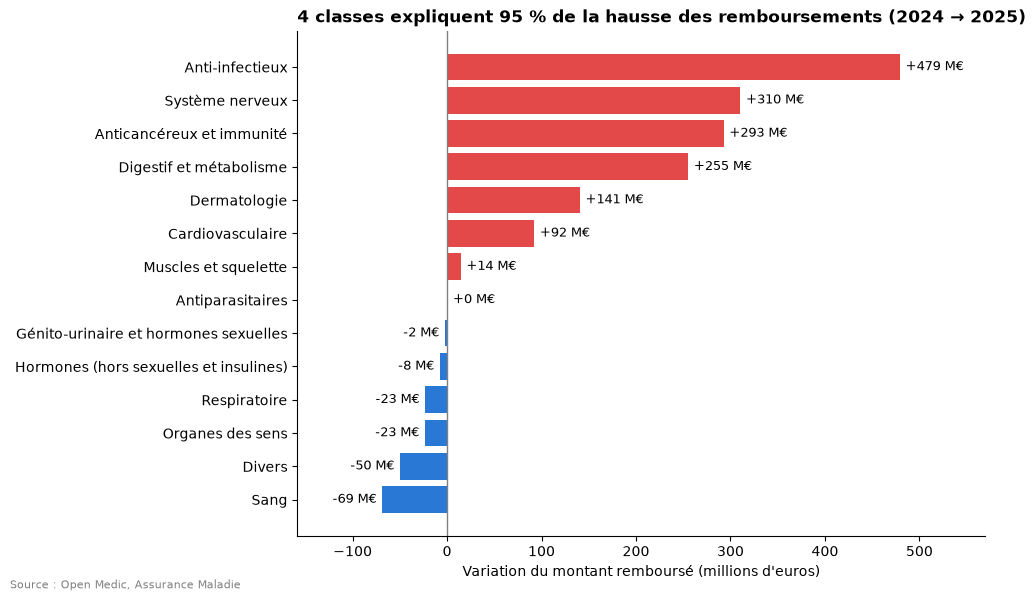

In [43]:
# 6.1 Graphique : contribution de chaque classe à la hausse
donnees = par_classe["hausse_M€"].sort_values()
couleurs = ["#e34948" if v > 0 else "#2a78d6" for v in donnees]   # rouge = hausse, bleu = baisse

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(donnees.index, donnees.values, color=couleurs)
ax.axvline(0, color="grey", linewidth=1)   # ligne du zéro

# Afficher la valeur au bout de chaque barre
for i, v in enumerate(donnees.values):
    ax.text(v + (6 if v >= 0 else -6), i, f"{v:+.0f} M€",
            va="center", ha="left" if v >= 0 else "right", fontsize=9)

ax.set_xlim(donnees.min() - 90, donnees.max() + 90)
ax.set_title("4 classes expliquent 95 % de la hausse des remboursements (2024 → 2025)",
             loc="left", fontweight="bold")
ax.set_xlabel("Variation du montant remboursé (millions d'euros)")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Source : Open Medic, Assurance Maladie", fontsize=8, color="grey")

plt.tight_layout()
plt.savefig("../images/6_1_hausse_par_classe.png", dpi=150, bbox_inches="tight")
plt.show()

**À retenir :** la hausse est concentrée sur quatre classes, dont les anti-infectieux en tête. Pour l'Assurance Maladie, piloter la dépense passe donc par un suivi ciblé de quelques classes, plutôt que par des mesures générales sur tous les médicaments.

### 6.2 Les molécules qui portent la hausse
Les 10 molécules dont le montant remboursé augmente le plus entre 2024 et 2025. Vérification des hypothèses H3 (anti-infectieux) et H4 (dermatologie).

In [44]:
# 6.2 Les 10 molécules qui contribuent le plus à la hausse (en millions d'euros)
par_molecule = df.pivot_table(index="ATC5", columns="annee", values="REM",
                              aggfunc="sum", fill_value=0) / 1e6
par_molecule["hausse_M€"] = par_molecule[2025] - par_molecule[2024]

# Ajouter le nom de la molécule et sa classe
infos = df.drop_duplicates("ATC5").set_index("ATC5")[["L_ATC5", "classe"]]
par_molecule = par_molecule.join(infos)

top10 = par_molecule.sort_values("hausse_M€", ascending=False).head(10)
top10[["L_ATC5", "classe", 2024, 2025, "hausse_M€"]].round(1)

,L_ATC5,classe,2024,2025,hausse_M€
ATC5,,,,,
J07BK03,ANTIGENE PURIFIE DE VIRUS DU ZONA,Anti-infectieux,0.0,319.3,319.3
N07XX08,TAFAMIDIS,Système nerveux,860.3,1071.3,211.0
S01LA05,AFLIBERCEPT,Organes des sens,499.8,604.9,105.1
D11AH05,DUPILUMAB,Dermatologie,343.5,434.8,91.3
A10BK01,DAPAGLIFLOZINE,Digestif et métabolisme,303.2,388.5,85.3
B01AF02,APIXABAN,Sang,805.6,885.4,79.8
A10BJ06,SEMAGLUTIDE,Digestif et métabolisme,271.1,348.1,77.0
L02BB06,DAROLUTAMIDE,Anticancéreux et immunité,90.7,161.4,70.7
J07AH08,ANTIGENES POLYSACCHARIDIQUES TRETRAVALENTS CON...,Anti-infectieux,11.0,76.7,65.7


**Constat :** 10 molécules concentrent 83 % de la hausse (+1 171 M€ sur +1 411 M€) : la hausse n'est pas générale, elle est portée par quelques traitements.
- **Nouveaux remboursements :** le vaccin contre le zona passe de 0 à 319 M€, c'est la première source de hausse.
- **Traitements très coûteux :** le tafamidis (maladie rare du cœur) dépasse 1 Md€ (+211 M€) ; deux anticancéreux récents ajoutent +136 M€.
- **Maladies chroniques fréquentes :** deux traitements du diabète (+162 M€), un anticoagulant (+80 M€), un traitement d'une maladie de l'œil liée à l'âge (+105 M€).
- **Dermatologie :** le dupilumab (eczéma sévère) ajoute +91 M€.

**Hypothèses :** H3 confirmée (les vaccins zona et méningite expliquent 80 % de la hausse des anti-infectieux) ; H4 confirmée (le dupilumab explique 65 % de la hausse en dermatologie).

**Point de vigilance :** l'aflibercept et l'apixaban augmentent alors que leur classe baisse. D'autres molécules de ces classes reculent, peut-être sous l'effet de génériques (à vérifier).

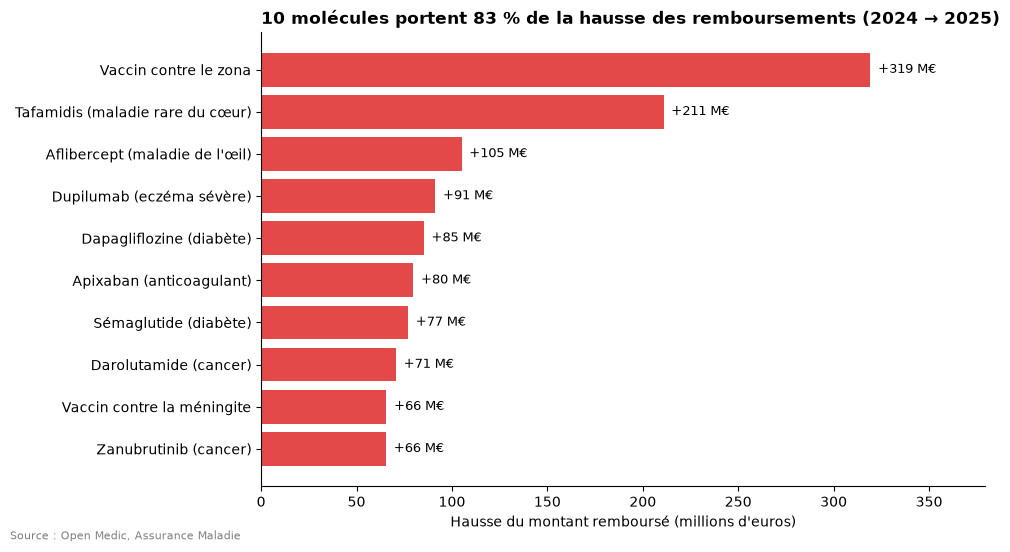

In [45]:
# 6.2 Graphique : les 10 molécules qui portent la hausse
# Noms courts et compréhensibles, écrits à la main (les libellés du fichier sont techniques)
noms_courts = {
    "J07BK03": "Vaccin contre le zona",
    "N07XX08": "Tafamidis (maladie rare du cœur)",
    "S01LA05": "Aflibercept (maladie de l'œil)",
    "D11AH05": "Dupilumab (eczéma sévère)",
    "A10BK01": "Dapagliflozine (diabète)",
    "B01AF02": "Apixaban (anticoagulant)",
    "A10BJ06": "Sémaglutide (diabète)",
    "L02BB06": "Darolutamide (cancer)",
    "J07AH08": "Vaccin contre la méningite",
    "L01EL03": "Zanubrutinib (cancer)",
}
donnees = top10["hausse_M€"].rename(index=noms_courts).sort_values()

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(donnees.index, donnees.values, color="#e34948")
for i, v in enumerate(donnees.values):
    ax.text(v + 4, i, f"+{v:.0f} M€", va="center", fontsize=9)

ax.set_xlim(0, donnees.max() + 60)
ax.set_title("10 molécules portent 83 % de la hausse des remboursements (2024 → 2025)",
             loc="left", fontweight="bold")
ax.set_xlabel("Hausse du montant remboursé (millions d'euros)")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Source : Open Medic, Assurance Maladie", fontsize=8, color="grey")

plt.tight_layout()
plt.savefig("../images/6_2_hausse_par_molecule.png", dpi=150, bbox_inches="tight")
plt.show()

**À retenir :** la hausse vient de trois sources différentes : un nouveau remboursement (le vaccin contre le zona), des traitements innovants très coûteux (maladies rares, cancers) et des maladies chroniques fréquentes (diabète, anticoagulants). Chacune appelle une réponse différente : la première est un choix de santé publique, la deuxième relève de la négociation des prix avec les laboratoires, la troisième du bon usage et du développement des génériques.

### 6.3 La dépense selon l'âge et le sexe des patients
Part de chaque tranche d'âge et de chaque sexe dans le montant remboursé, et évolution entre 2024 et 2025. Vérification de l'hypothèse H5.

In [46]:
# 6.3 Montant remboursé par tranche d'âge (en millions d'euros)
par_age = df.pivot_table(index="tranche_age", columns="annee", values="REM", aggfunc="sum") / 1e6

par_age["part_2025_%"] = par_age[2025] / par_age[2025].sum() * 100
par_age["evolution_%"] = (par_age[2025] / par_age[2024] - 1) * 100
par_age["part_hausse_%"] = (par_age[2025] - par_age[2024]) / (par_age[2025] - par_age[2024]).sum() * 100

par_age.round(1)

annee,2024,2025,part_2025_%,evolution_%,part_hausse_%
tranche_age,,,,,
0-19 ans,1881.2,2001.0,7.3,6.4,8.5
20-59 ans,8956.1,9157.4,33.4,2.2,14.3
60 ans et plus,15164.3,16266.9,59.3,7.3,78.2
Inconnu,30.2,17.2,0.1,-43.1,-0.9


**Constat :** les 60 ans et plus concentrent 59 % de la dépense 2025 (16,3 Md€) et portent 78 % de la hausse (+7,3 % en un an). Les 20-59 ans progressent peu (+2,2 %) ; les 0-19 ans pèsent peu (7 %) mais progressent nettement (+6,4 %), peut-être sous l'effet de la vaccination contre la méningite (à vérifier). Cohérent avec la 6.2 : la plupart des molécules en hausse visent des maladies liées à l'âge.

**Hypothèse H5 confirmée :** les 60 ans et plus concentrent la dépense et la majorité de la hausse.

In [47]:
# 6.3 Montant remboursé par sexe (en millions d'euros)
par_sexe = df.pivot_table(index="sexe_lib", columns="annee", values="REM", aggfunc="sum") / 1e6

par_sexe["part_2025_%"] = par_sexe[2025] / par_sexe[2025].sum() * 100
par_sexe["evolution_%"] = (par_sexe[2025] / par_sexe[2024] - 1) * 100
par_sexe["part_hausse_%"] = (par_sexe[2025] - par_sexe[2024]) / (par_sexe[2025] - par_sexe[2024]).sum() * 100

par_sexe.round(1)

annee,2024,2025,part_2025_%,evolution_%,part_hausse_%
sexe_lib,,,,,
Femme,12396.0,13019.9,47.4,5.0,44.2
Homme,13583.3,14364.7,52.3,5.8,55.4
Inconnu,52.5,57.9,0.2,10.2,0.4


**Constat :** les hommes concentrent 52 % de la dépense 2025 (14,4 Md€) et 55 % de la hausse (+5,8 %, contre +5,0 % pour les femmes), alors que les femmes ont plus de lignes de prescription. Les hommes ont donc des traitements plus coûteux en moyenne. Hypothèse : certains traitements en forte hausse visent des maladies plus fréquentes chez les hommes (cancer de la prostate notamment).

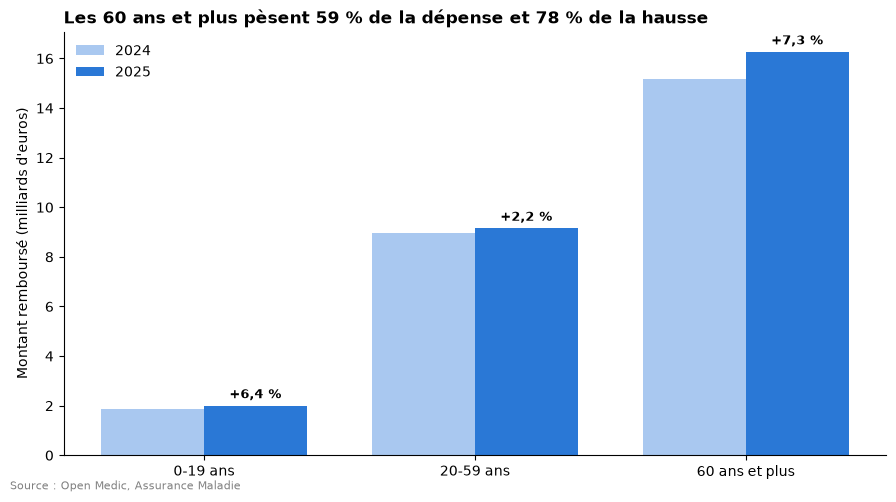

In [48]:
# 6.3 Graphique : montant remboursé par tranche d'âge, 2024 et 2025
donnees = par_age.drop(index="Inconnu")[[2024, 2025]] / 1000   # en milliards d'euros

x = np.arange(len(donnees))   # position de chaque tranche sur l'axe
largeur = 0.38
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - largeur/2, donnees[2024], largeur, label="2024", color="#a9c8f0")
ax.bar(x + largeur/2, donnees[2025], largeur, label="2025", color="#2a78d6")

# Afficher l'évolution au-dessus de chaque barre 2025
for i, tranche in enumerate(donnees.index):
    evol = (donnees.loc[tranche, 2025] / donnees.loc[tranche, 2024] - 1) * 100
    ax.text(i + largeur/2, donnees.loc[tranche, 2025] + 0.3,
            f"{evol:+.1f} %".replace(".", ","), ha="center", fontsize=9, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(donnees.index)
ax.set_ylabel("Montant remboursé (milliards d'euros)")
ax.set_title("Les 60 ans et plus pèsent 59 % de la dépense et 78 % de la hausse",
             loc="left", fontweight="bold")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Source : Open Medic, Assurance Maladie", fontsize=8, color="grey")

plt.tight_layout()
plt.savefig("../images/6_3_depense_par_age.png", dpi=150, bbox_inches="tight")
plt.show()

**À retenir :** la dépense de médicaments est d'abord une dépense liée à l'âge : les 60 ans et plus en concentrent près de 6 euros sur 10, et leur part augmente. Avec le vieillissement de la population, cette tendance devrait se poursuivre : c'est un enjeu durable pour le financement de l'Assurance Maladie.

### 6.4 Le Centre-Val de Loire face à la tendance nationale
Évolution du montant remboursé par région entre 2024 et 2025, puis comparaison des indicateurs clés du Centre-Val de Loire avec la France entière. Vérification de l'hypothèse H6.

In [49]:
# 6.4 Montant remboursé par région et évolution 2024 → 2025 (en millions d'euros)
par_region = df.pivot_table(index="region", columns="annee", values="REM", aggfunc="sum") / 1e6
par_region["evolution_%"] = (par_region[2025] / par_region[2024] - 1) * 100

par_region.sort_values("evolution_%", ascending=False).round(1)

annee,2024,2025,evolution_%
region,,,
Inconnu,1026.2,1129.4,10.1
Code 5 (à confirmer),734.5,794.7,8.2
Bretagne,1217.9,1297.7,6.5
Centre-Val de Loire,922.8,976.9,5.9
Pays de la Loire,1304.1,1379.5,5.8
Hauts-de-France,2290.2,2418.4,5.6
Occitanie,2361.6,2493.4,5.6
Normandie,1249.4,1317.8,5.5
Nouvelle-Aquitaine,2390.1,2516.9,5.3


**Constat :** le Centre-Val de Loire progresse de +5,9 % (977 M€ en 2025), un peu plus vite que la moyenne nationale (+5,4 %). C'est la 2e plus forte hausse des régions identifiées, après la Bretagne (+6,5 %) ; PACA (+3,8 %) et l'Île-de-France (+4,5 %) progressent le moins. Les écarts entre régions restent faibles. Point de vigilance : 4 % de la dépense (1,1 Md€) n'est rattachée à aucune région, et le code 5 reste à identifier.

**Hypothèse H6 confirmée, avec une nuance :** le Centre-Val de Loire suit la tendance nationale, légèrement au-dessus.

In [50]:
# 6.4 Indicateurs clés : Centre-Val de Loire et France entière
def indicateurs(d):
    res = d.groupby("annee").agg(REM=("REM", "sum"), BOITES=("BOITES", "sum"))
    res["cout_par_boite_€"] = res["REM"] / res["BOITES"]

    gen = d.groupby(["annee", "statut_gen"])["BOITES"].sum().unstack()
    res["part_generiques_%"] = gen["Générique"] / (gen["Générique"] + gen["Princeps"]) * 100

    seniors = d[d["tranche_age"] == "60 ans et plus"].groupby("annee")["REM"].sum()
    res["part_60_ans_et_plus_%"] = seniors / res["REM"] * 100

    res["REM"] = res["REM"] / 1e6   # en millions d'euros
    return res

comparaison = pd.concat({
    "France": indicateurs(df),
    "Centre-Val de Loire": indicateurs(df[df["region"] == "Centre-Val de Loire"]),
})
comparaison.round(1)

REM      BOITES  cout_par_boite_€  \
                    annee                                          
France              2024   26031.9  2367965230              11.0   
                    2025   27442.4  2326805025              11.8   
Centre-Val de Loire 2024     922.8    89919102              10.3   
                    2025     976.9    88110068              11.1   

                           part_generiques_%  part_60_ans_et_plus_%  
                    annee                                            
France              2024                49.3                   58.3  
                    2025                50.1                   59.3  
Centre-Val de Loire 2024                50.1                   63.7  
                    2025                50.8                   64.7

**Constat :** en Centre-Val de Loire, les 60 ans et plus représentent 64,7 % de la dépense, contre 59,3 % en France. Comme ils portent l'essentiel de la hausse (section 6.3), c'est l'explication la plus probable de la progression régionale plus rapide. La région utilise pourtant un peu plus de génériques (50,8 % contre 50,1 %) et son coût par boîte reste inférieur à la moyenne (11,1 € contre 11,8 €). La hausse régionale relève donc davantage de l'âge des patients que d'un défaut de maîtrise des dépenses.

In [51]:
# 6.4 Part des 60 ans et plus dans la dépense 2025, par région
d25 = df[df["annee"] == 2025]
part_60_region = (d25[d25["tranche_age"] == "60 ans et plus"].groupby("region")["REM"].sum()
                  / d25.groupby("region")["REM"].sum() * 100)

part_60_region.drop(index=["Inconnu", "Code 5 (à confirmer)"]).sort_values(ascending=False).round(1)

region
Bourgogne-Franche-Comté       66.1
Nouvelle-Aquitaine            65.3
Centre-Val de Loire           64.7
Occitanie                     63.6
Bretagne                      63.2
Provence-Alpes-Côte d'Azur    63.0
Pays de la Loire              62.7
Normandie                     62.1
Grand Est                     60.8
Auvergne-Rhône-Alpes          60.0
Hauts-de-France               57.4
Île-de-France                 51.9
Name: REM, dtype: float64

**Constat :** le Centre-Val de Loire est la 3e région où les 60 ans et plus pèsent le plus dans la dépense (64,7 %), derrière la Bourgogne-Franche-Comté et la Nouvelle-Aquitaine. Ce résultat est cohérent avec le tableau de bord Power BI.

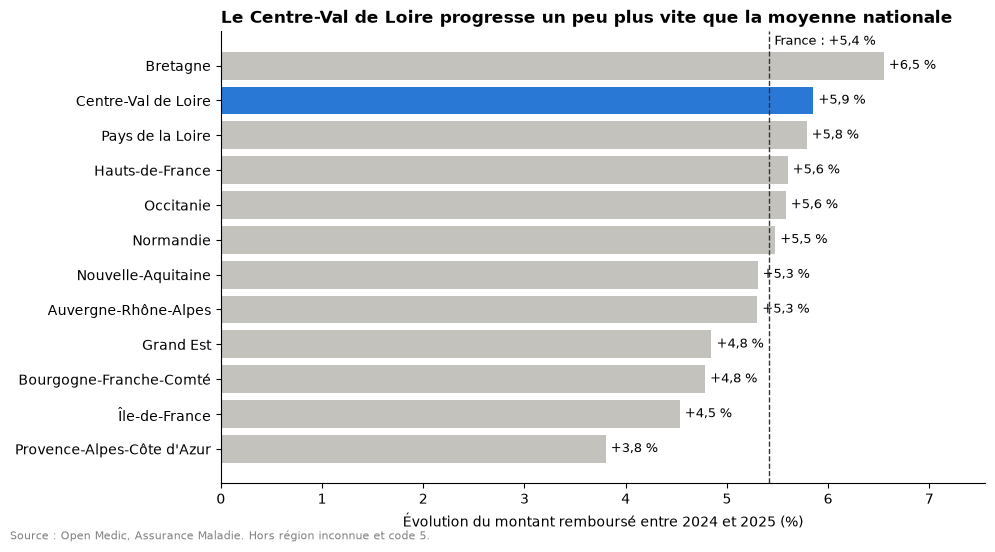

In [52]:
# 6.4 Graphique : évolution par région, Centre-Val de Loire mis en évidence
evol_france = df.groupby("annee")["REM"].sum().pct_change().iloc[-1] * 100

donnees = (par_region.drop(index=["Inconnu", "Code 5 (à confirmer)"])["evolution_%"]
           .sort_values())
couleurs = ["#2a78d6" if r == "Centre-Val de Loire" else "#c3c2bd" for r in donnees.index]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(donnees.index, donnees.values, color=couleurs)
ax.axvline(evol_france, color="#333333", linestyle="--", linewidth=1)   # moyenne nationale
ax.text(evol_france + 0.05, len(donnees) - 0.4,
        f"France : +{evol_france:.1f} %".replace(".", ","), fontsize=9)
for i, v in enumerate(donnees.values):
    ax.text(v + 0.05, i, f"+{v:.1f} %".replace(".", ","), va="center", fontsize=9)

ax.set_xlim(0, donnees.max() + 1)
ax.set_title("Le Centre-Val de Loire progresse un peu plus vite que la moyenne nationale",
             loc="left", fontweight="bold")
ax.set_xlabel("Évolution du montant remboursé entre 2024 et 2025 (%)")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Source : Open Medic, Assurance Maladie. Hors région inconnue et code 5.",
         fontsize=8, color="grey")

plt.tight_layout()
plt.savefig("../images/6_4_evolution_par_region.png", dpi=150, bbox_inches="tight")
plt.show()

**À retenir :** toutes les régions progressent, dans une fourchette serrée (+3,8 % à +6,5 %). Le Centre-Val de Loire fait partie des plus dynamiques, non par une moindre maîtrise des dépenses, mais parce que sa population de patients est plus âgée. Pour les acteurs régionaux de santé, c'est une hausse à anticiper durablement.

## 7. Validation des chiffres clés en SQL
Recalcul des principaux résultats avec DuckDB (SQL), pour vérifier qu'ils sont identiques à ceux obtenus avec Pandas.

In [53]:
# 7.1 Totaux par année en SQL
requete_totaux = """
SELECT annee,
       ROUND(SUM(REM) / 1e6, 1)              AS rem_millions,
       SUM(BOITES)                           AS boites,
       ROUND(SUM(REM) / SUM(BOITES), 2)      AS cout_par_boite
FROM df
GROUP BY annee
ORDER BY annee
"""
totaux_sql = duckdb.sql(requete_totaux).df()
totaux_sql

,annee,rem_millions,boites,cout_par_boite
0,2024,26031.9,2.367965e+09,10.99
1,2025,27442.4,2.326805e+09,11.79


In [54]:
# Contrôle automatique : SQL et Pandas doivent donner les mêmes totaux
totaux_pandas = df.groupby("annee")["REM"].sum() / 1e6
ecart = (totaux_sql.set_index("annee")["rem_millions"] - totaux_pandas.round(1)).abs().max()
print(f"Écart maximal SQL / Pandas : {ecart:.2f} M€")
assert ecart < 0.1, "Attention : SQL et Pandas ne donnent pas le même résultat !"

Écart maximal SQL / Pandas : 0.00 M€


In [55]:
# 7.2 Les 10 molécules qui portent la hausse, en SQL
requete_molecules = """
SELECT ATC5,
       ROUND(SUM(CASE WHEN annee = 2024 THEN REM ELSE 0 END) / 1e6, 1) AS rem_2024,
       ROUND(SUM(CASE WHEN annee = 2025 THEN REM ELSE 0 END) / 1e6, 1) AS rem_2025,
       ROUND((SUM(CASE WHEN annee = 2025 THEN REM ELSE 0 END)
            - SUM(CASE WHEN annee = 2024 THEN REM ELSE 0 END)) / 1e6, 1) AS hausse_millions
FROM df
GROUP BY ATC5
ORDER BY hausse_millions DESC
LIMIT 10
"""
duckdb.sql(requete_molecules).df()

,ATC5,rem_2024,rem_2025,hausse_millions
0,J07BK03,0.0,319.3,319.3
1,N07XX08,860.3,1071.3,211.0
2,S01LA05,499.8,604.9,105.1
3,D11AH05,343.5,434.8,91.3
4,A10BK01,303.2,388.5,85.3
5,B01AF02,805.6,885.4,79.8
6,A10BJ06,271.1,348.1,77.0
7,L02BB06,90.7,161.4,70.7
8,J07AH08,11.0,76.7,65.7
9,L01EL03,41.7,107.3,65.5


**Constat :** les totaux par année et les 10 molécules qui portent la hausse sont strictement identiques en SQL (DuckDB) et en Pandas (écart de 0,00 M€). Les chiffres clés de l'analyse sont validés par deux outils indépendants.

In [56]:
# 7.3 Centre-Val de Loire : évolution et part des 60 ans et plus, en SQL
requete_region = """
SELECT annee,
       ROUND(SUM(REM) / 1e6, 1) AS rem_millions,
       ROUND(100.0 * SUM(CASE WHEN tranche_age = '60 ans et plus' THEN REM ELSE 0 END)
             / SUM(REM), 1) AS part_60_ans_et_plus
FROM df
WHERE region = 'Centre-Val de Loire'
GROUP BY annee
ORDER BY annee
"""
duckdb.sql(requete_region).df()

,annee,rem_millions,part_60_ans_et_plus
0,2024,922.8,63.7
1,2025,976.9,64.7


**Constat :** les chiffres du Centre-Val de Loire (montant remboursé et part des 60 ans et plus) sont également identiques en SQL et en Pandas.

In [57]:
# 7.4 Enregistrer les requêtes SQL dans le dossier sql/ (pour GitHub)
from pathlib import Path

requetes = {
    "01_totaux_par_annee.sql": requete_totaux,
    "02_top10_molecules_hausse.sql": requete_molecules,
    "03_centre_val_de_loire.sql": requete_region,
}
for nom, texte in requetes.items():
    Path("../sql", nom).write_text(texte.strip() + "\n", encoding="utf-8")
    print("Enregistré :", nom)

Enregistré : 01_totaux_par_annee.sql
Enregistré : 02_top10_molecules_hausse.sql
Enregistré : 03_centre_val_de_loire.sql


## 8. Export des tableaux résumés pour Power BI
Deux tableaux légers, regroupés à partir des 3,8 millions de lignes : une synthèse par profil (classe, âge, sexe, région, statut générique) et un détail par molécule.

In [58]:
# 8.1 Synthèse par année, classe, âge, sexe, région et statut générique
import os
os.makedirs("../data/clean", exist_ok=True)

synthese = (df.groupby(["annee", "classe", "tranche_age", "sexe_lib", "region", "statut_gen"],
                       as_index=False)[["REM", "BSE", "BOITES"]].sum())

# Noms de colonnes explicites pour Power BI
synthese = synthese.rename(columns={
    "sexe_lib": "sexe",
    "statut_gen": "statut_generique",
    "REM": "montant_rembourse",
    "BSE": "base_remboursement",
    "BOITES": "nb_boites",
})

# Contrôle : les totaux ne doivent pas changer
ecart = abs(synthese["montant_rembourse"].sum() - df["REM"].sum())
print(synthese.shape, f"- écart : {ecart:.2f} €")
assert ecart < 1, "Attention : le total a changé !"

synthese.to_csv("../data/clean/synthese_depenses.csv", sep=";", decimal=",",
                index=False, encoding="utf-8-sig")

(8287, 9) - écart : 0.00 €


In [59]:
# 8.2 Détail par année et par molécule
molecules = df.groupby(["annee", "ATC5"], as_index=False)[["REM", "BOITES"]].sum()

# Ajouter un seul nom et une seule classe par molécule (les noms peuvent varier d'une année à l'autre)
molecules = molecules.merge(infos.reset_index(), on="ATC5", how="left")

molecules = molecules.rename(columns={
    "ATC5": "code_molecule",
    "L_ATC5": "molecule",
    "REM": "montant_rembourse",
    "BOITES": "nb_boites",
})

# Contrôles : total inchangé, et chaque molécule a bien un nom
ecart = abs(molecules["montant_rembourse"].sum() - df["REM"].sum())
print(molecules.shape, f"- écart : {ecart:.2f} €",
      f"- molécules sans nom : {molecules['molecule'].isna().sum()}")
assert ecart < 1, "Attention : le total a changé !"

molecules.to_csv("../data/clean/depenses_par_molecule.csv", sep=";", decimal=",",
                 index=False, encoding="utf-8-sig")

(2336, 6) - écart : 0.00 € - molécules sans nom : 0


**Constat :** deux tableaux exportés dans `data/clean`, avec des totaux identiques à l'analyse (écart de 0,00 €) :
- `synthese_depenses.csv` : 8 287 lignes (année, classe, âge, sexe, région, statut générique)
- `depenses_par_molecule.csv` : 2 336 lignes (année, molécule, classe)

Ces fichiers sont légers : contrairement aux données brutes, ils peuvent être publiés sur GitHub.

## 9. Conclusions

### 9.1 Réponse à la question métier
**Entre 2024 et 2025, les dépenses de médicaments remboursés en pharmacie de ville passent de 26,0 à 27,4 Md€ (+5,4 %, soit +1,4 Md€), alors que le nombre de boîtes baisse de 1,7 %.**

La hausse ne vient donc pas d'une consommation plus forte, mais d'un **coût moyen par boîte plus élevé** (+7,3 %, de 10,99 € à 11,79 €). Ce coût augmente parce que la dépense se déplace vers des traitements plus chers :
- **Une hausse très concentrée :** 4 classes de médicaments expliquent 95 % de la hausse, et 10 molécules à elles seules 83 %.
- **Trois moteurs distincts :** un nouveau remboursement (le vaccin contre le zona, de 0 à 319 M€), des traitements innovants très coûteux (maladie rare du cœur, cancers) et des maladies chroniques fréquentes (diabète, anticoagulants).
- **Une dépense liée à l'âge :** les 60 ans et plus représentent 59 % de la dépense et portent 78 % de la hausse.
- **Le Centre-Val de Loire suit la tendance, un peu au-dessus** (+5,9 %), principalement parce que sa population de patients est plus âgée (65 % de la dépense pour les 60 ans et plus, contre 59 % en France).

### 9.2 Verdict des hypothèses
| N° | Hypothèse | Verdict | Ce que montrent les données |
|---|---|---|---|
| H1 | La hausse vient du coût par boîte, pas du nombre de boîtes | ✅ Confirmée | Le nombre de boîtes baisse de 1,7 %, tandis que le coût moyen par boîte augmente de 7,3 %. |
| H2 | La part des génériques progresse | ✅ Confirmée | Les génériques passent de 49,3 % à 50,1 % des boîtes, mais cette progression ne suffit pas à compenser la hausse. |
| H3 | La hausse des anti-infectieux vient des vaccins ou des antiviraux | ✅ Confirmée | Deux vaccins, contre le zona et contre la méningite, expliquent à eux seuls 80 % de la hausse de cette classe. |
| H4 | La hausse en dermatologie vient de nouveaux traitements coûteux | ✅ Confirmée | Un seul traitement de l'eczéma sévère, le dupilumab, explique près des deux tiers de la hausse. |
| H5 | Les 60 ans et plus concentrent la dépense | ✅ Confirmée | Ils représentent 59 % de la dépense et portent près de 8 euros sur 10 de la hausse. |
| H6 | Le Centre-Val de Loire suit la tendance nationale | ✅ Confirmée, avec une nuance | La région progresse un peu plus vite que la France (+5,9 % contre +5,4 %), car sa population de patients est plus âgée. |

*H1 et H2 ont été formulées pendant l'exploration des données, les autres lors du cadrage.*

### 9.3 Recommandations
- **Suivre une liste courte de molécules :** 10 molécules portent 83 % de la hausse. Un suivi régulier de ces traitements permettrait de détecter tôt les dérives, plutôt qu'un suivi global de tous les médicaments.
- **Anticiper le coût des nouveaux remboursements :** le vaccin contre le zona représente à lui seul 319 M€ dès sa première année. Chaque nouveau remboursement devrait être accompagné d'une estimation de son impact sur plusieurs années.
- **Poursuivre le développement des génériques :** leur part progresse (+0,8 point), mais trop lentement pour compenser la hausse. Le levier reste utile sur les maladies chroniques fréquentes, comme le diabète ou les anticoagulants.
- **Intégrer le vieillissement dans les prévisions régionales :** en Centre-Val de Loire, la part plus élevée des 60 ans et plus annonce une dépense qui continuera de croître plus vite que la moyenne. Les acteurs régionaux de santé ont intérêt à l'anticiper dans leurs budgets.

### 9.4 Cadre de l'étude et points de vigilance
- **Périmètre :** seuls les médicaments délivrés en pharmacie de ville sont couverts, pas ceux délivrés à l'hôpital.
- **Pas de nombre de patients :** une ligne regroupe un médicament et un profil de patients. Le coût par patient ne peut donc pas être calculé.
- **Codes interprétés :** la signification de certains codes (`TOP_GEN` 0, 1 et 4, région code 5, tranches d'âge) est à confirmer avec le descriptif officiel des variables.
- **Part des génériques :** elle est calculée sur tous les médicaments, y compris ceux sans générique disponible. Ce n'est pas le taux officiel de substitution.
- **Données masquées :** pour protéger l'anonymat des patients, certaines valeurs sont remplacées par « inconnu ». Par exemple, 4 % de la dépense n'est rattachée à aucune région.
- **Prescripteurs non analysés :** les codes de spécialité ont changé entre 2024 et 2025, ce qui empêche une comparaison fiable.
- **Deux années seulement :** les tendances observées sont à confirmer sur une période plus longue.
- **Explications externes :** certaines interprétations (vaccination devenue obligatoire, maladies plus fréquentes chez les hommes) ne sont pas vérifiables avec ces seules données et restent des hypothèses.